<a href="https://colab.research.google.com/github/IvMatic/fraud-ring-detection-ml/blob/main/notebooks/04_feature_ablation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# EXP-003 — Feature Ablation Study

## Research Question
How does removing individual account features affect
Isolation Forest anomaly detection performance?

## Hypothesis
Removing informative features may reduce detection
performance, especially for subtle anomalies.

## Methodology
Train separate Isolation Forest models using four
feature subsets, while keeping the data split
and model configuration consistent.

## Dataset
Synthetic Account Dataset v2.


In [2]:

from google.colab import drive
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/fraud-ring-detection-ml"
)

df = pd.read_csv(
    PROJECT_ROOT / "data/raw/synthetic_accounts_v2.csv"
)

print("Dataset shape:", df.shape)
display(df.head())


Mounted at /content/drive
Dataset shape: (1000, 6)


,account_id,num_devices,num_transactions_24h,connected_accounts,anomaly_type,is_synthetic_anomaly
0,ACC_00001,0,7,5,normal,0
1,ACC_00002,0,13,4,normal,0
2,ACC_00003,3,15,7,normal,0
3,ACC_00004,2,11,2,normal,0
4,ACC_00005,2,6,4,normal,0


In [5]:

feature_sets = {
    "all_features": [
        "num_devices",
        "num_transactions_24h",
        "connected_accounts"
    ],
    "without_connected_accounts": [
        "num_devices",
        "num_transactions_24h"
    ],
    "without_num_devices": [
        "num_transactions_24h",
        "connected_accounts"
    ],
    "without_transactions": [
        "num_devices",
        "connected_accounts"
    ]
}

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=42,
    stratify=df["anomaly_type"]
)

print("Train size:", len(train_idx))
print("Test size:", len(test_idx))


Train size: 800
Test size: 200


In [6]:

results = []

for name, features in feature_sets.items():

    X_train = df.loc[train_idx, features]
    X_test = df.loc[test_idx, features]
    y_test = df.loc[
        test_idx, "is_synthetic_anomaly"
    ]

    model = IsolationForest(
        n_estimators=100,
        max_samples="auto",
        contamination=0.06,
        random_state=42
    )

    model.fit(X_train)

    y_pred = (
        model.predict(X_test) == -1
    ).astype(int)

    # Recall for subtle anomalies
    subtle_mask = (
        df.loc[test_idx, "anomaly_type"] == "subtle"
    )

    subtle_recall = (
        y_pred[subtle_mask.to_numpy()].mean()
    )

    results.append({
        "feature_set": name,
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "subtle_recall": subtle_recall
    })

results_df = pd.DataFrame(results)

display(results_df)


,feature_set,precision,recall,f1_score,subtle_recall
0,all_features,0.846154,0.916667,0.880000,0.833333
1,without_connected_accounts,0.555556,0.833333,0.666667,0.666667
2,without_num_devices,1.000000,0.833333,0.909091,0.666667
3,without_transactions,0.750000,0.750000,0.750000,0.500000


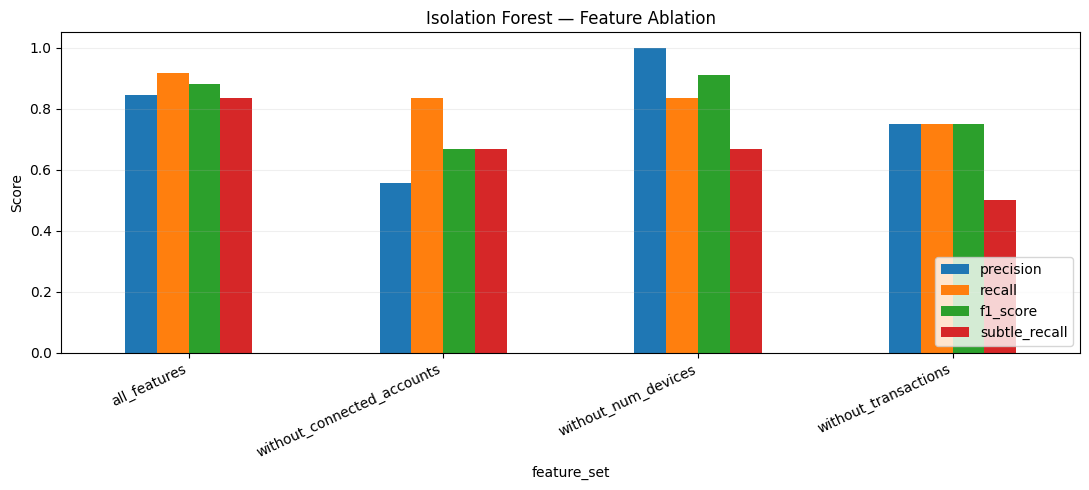

In [7]:

results_df.set_index("feature_set")[
    ["precision", "recall", "f1_score", "subtle_recall"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Isolation Forest — Feature Ablation")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


In [8]:

prediction_comparison = df.loc[
    test_idx,
    ["account_id", "anomaly_type"]
].copy()

for name, features in feature_sets.items():

    X_train = df.loc[train_idx, features]
    X_test = df.loc[test_idx, features]

    model = IsolationForest(
        n_estimators=100,
        max_samples="auto",
        contamination=0.06,
        random_state=42
    )

    model.fit(X_train)

    prediction_comparison[name] = (
        model.predict(X_test) == -1
    ).astype(int)

# Focus on subtle anomalies
subtle_comparison = prediction_comparison[
    prediction_comparison["anomaly_type"] == "subtle"
]

display(subtle_comparison)


,account_id,anomaly_type,all_features,without_connected_accounts,without_num_devices,without_transactions
13,ACC_00014,subtle,1,1,1,1
618,ACC_00619,subtle,0,0,0,0
86,ACC_00087,subtle,1,1,1,1
616,ACC_00617,subtle,1,1,1,0
662,ACC_00663,subtle,1,1,0,0
872,ACC_00873,subtle,1,0,1,1



## Findings and Interpretation

### Key Results

The feature ablation study compared four Isolation
Forest models trained on different feature subsets.

The model without `num_devices` achieved the highest
overall F1-score (0.909), but its subtle anomaly
recall was lower than the full-feature baseline.

The full-feature model achieved the highest subtle
anomaly recall (0.833).

### Per-Account Analysis

All four models failed to detect ACC_00619.

Other subtle anomalies showed different prediction
patterns depending on the selected features.

This indicates that feature selection affects not
only aggregate evaluation metrics but also which
individual observations are detected.

### What I Learned

- Higher F1-score does not necessarily mean better
  detection of the anomaly type of greatest interest.
- Removing features changes Isolation Forest behavior.
- Different models may detect different observations.
- Combining models cannot recover an anomaly that
  every individual model misses.
- Feature ablation is useful for investigating model
  sensitivity, but it does not establish causality.

### Limitations

- The dataset is synthetic and intentionally designed.
- Only six subtle anomalies were present in the test set.
- Results were obtained from a single train/test split.
- Feature subsets were compared using test labels;
  a separate validation set is needed for model selection.
- Model variants are correlated and may not provide
  sufficient diversity for an effective ensemble.

### Next Steps

1. Document the feature ablation experiment.
2. Explore feature engineering for missed anomalies.
3. Compare Isolation Forest with other methods.
4. Move toward transaction and graph datasets.
